In [2]:



import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

print("Libraries imported successfully!")




Libraries imported successfully!


In [3]:

data = {
    "ticket": [
        # Network
        "I cannot connect to the company VPN",
        "VPN connection keeps failing",
        "The office WiFi is not working",
        "Internet connection keeps dropping",
        "Unable to connect to the office network",
        "Network connectivity is very slow",
        "Cannot access websites on the company network",
        "Remote desktop disconnects frequently",
        "The VPN says connection timed out",
        "My laptop has no internet connection",

        # Access
        "I cannot log in to my account",
        "My password reset is not working",
        "I need access to my email account",
        "My account is locked",
        "I forgot my company password",
        "Login failed with invalid credentials",
        "Please grant me access to a shared folder",
        "I cannot access the employee portal",
        "My account authentication is failing",
        "I need permission to open a company application",

        # Software
        "Laptop software keeps crashing",
        "The application is not opening",
        "The software shows an error",
        "Unable to install the application",
        "Microsoft Teams keeps crashing",
        "Outlook is not responding",
        "The application freezes when I open it",
        "Software update failed to install",
        "Excel closes unexpectedly",
        "The application displays an unexpected error",

        # Hardware
        "Printer is not responding",
        "My monitor screen is blank",
        "Laptop is running very slowly",
        "Keyboard is not working",
        "My computer will not turn on",
        "The mouse is not responding",
        "Laptop screen is flickering",
        "Printer is producing blank pages",
        "My laptop battery is not charging",
        "The computer fan is making unusual noise"
    ],
    "category": (
        ["Network"] * 10 +
        ["Access"] * 10 +
        ["Software"] * 10 +
        ["Hardware"] * 10
    )
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Total tickets:", len(df))
df.head()


Dataset created successfully!
Total tickets: 40


,ticket,category
0,I cannot connect to the company VPN,Network
1,VPN connection keeps failing,Network
2,The office WiFi is not working,Network
3,Internet connection keeps dropping,Network
4,Unable to connect to the office network,Network


In [4]:

print("Dataset size:", df.shape)

print("\nTickets in each category:")
print(df["category"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())


Dataset size: (40, 2)

Tickets in each category:
category
Network     10
Access      10
Software    10
Hardware    10
Name: count, dtype: int64

Missing values:
ticket      0
category    0
dtype: int64


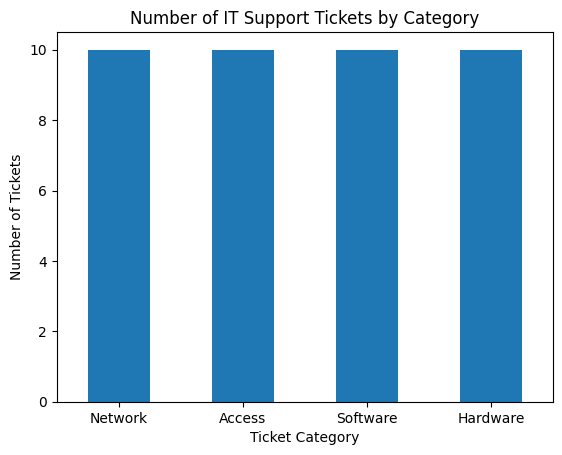

In [5]:

df["category"].value_counts().plot(kind="bar")

plt.title("Number of IT Support Tickets by Category")
plt.xlabel("Ticket Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.show()


In [6]:

# Separate ticket descriptions and categories
X = df["ticket"]
y = df["category"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Create the machine learning pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        C=10
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Total tickets:", len(df))
print("Training tickets:", len(X_train))
print("Testing tickets:", len(X_test))


Model trained successfully!
Total tickets: 40
Training tickets: 30
Testing tickets: 10


In [7]:

# Generate fresh predictions for the current test set
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.2%}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Network", "Access", "Software", "Hardware"],
    zero_division=0
))


Test accuracy: 90.00%

Classification report:
              precision    recall  f1-score   support

     Network       0.75      1.00      0.86         3
      Access       1.00      0.67      0.80         3
    Software       1.00      1.00      1.00         2
    Hardware       1.00      1.00      1.00         2

    accuracy                           0.90        10
   macro avg       0.94      0.92      0.91        10
weighted avg       0.93      0.90      0.90        10



In [8]:

results = pd.DataFrame({
    "Ticket": X_test,
    "Actual Category": y_test,
    "Predicted Category": y_pred
})

results = results.reset_index(drop=True)
print(results.to_string(index=False))


                                      Ticket Actual Category Predicted Category
            Printer is producing blank pages        Hardware           Hardware
         I cannot access the employee portal          Access            Network
                VPN connection keeps failing         Network            Network
   Please grant me access to a shared folder          Access             Access
     Unable to connect to the office network         Network            Network
    The computer fan is making unusual noise        Hardware           Hardware
         I cannot connect to the company VPN         Network            Network
                 The software shows an error        Software           Software
The application displays an unexpected error        Software           Software
                I forgot my company password          Access             Access


In [9]:

new_tickets = [
    "I cannot connect to the office WiFi",
    "I forgot my password and cannot log in",
    "Microsoft Teams keeps crashing",
    "My laptop screen is not working",
    "I cannot connect to the company VPN",
    "Please unlock my company account"
]

predictions = model.predict(new_tickets)

for ticket, category in zip(new_tickets, predictions):
    print("Ticket:", ticket)
    print("Predicted category:", category)
    print("-" * 40)


Ticket: I cannot connect to the office WiFi
Predicted category: Network
----------------------------------------
Ticket: I forgot my password and cannot log in
Predicted category: Access
----------------------------------------
Ticket: Microsoft Teams keeps crashing
Predicted category: Software
----------------------------------------
Ticket: My laptop screen is not working
Predicted category: Hardware
----------------------------------------
Ticket: I cannot connect to the company VPN
Predicted category: Network
----------------------------------------
Ticket: Please unlock my company account
Predicted category: Access
----------------------------------------


In [10]:

ticket = input("Enter an IT support ticket: ")

prediction = model.predict([ticket])

print("Predicted category:", prediction[0])


Enter an IT support ticket: I cannot connect to the company VPN
Predicted category: Network


In [11]:

# Step 10: Explore the words learned by the model

vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

print("Number of text features learned:", len(vectorizer.get_feature_names_out()))
print("\nCategories learned:", classifier.classes_)

print("\nExample words and phrases:")
print(vectorizer.get_feature_names_out()[:30])


Number of text features learned: 180

Categories learned: ['Access' 'Hardware' 'Network' 'Software']

Example words and phrases:
['access' 'access to' 'access websites' 'account' 'account authentication'
 'account is' 'application' 'application freezes' 'application is'
 'authentication' 'authentication is' 'battery' 'battery is' 'blank'
 'cannot' 'cannot access' 'cannot log' 'charging' 'closes'
 'closes unexpectedly' 'company' 'company application' 'company network'
 'computer' 'computer will' 'connection' 'connection keeps'
 'connection timed' 'connectivity' 'connectivity is']


In [12]:

import joblib

joblib.dump(model, "it_support_ticket_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [13]:

readme_content = """
# IT Support Ticket Classification Using Machine Learning

## Project Overview
This project uses Python and Machine Learning to classify IT support
tickets into four categories: Network, Access, Software, and Hardware.

## Problem Statement
IT support teams receive many tickets every day. Manually categorizing
each ticket can take time. This project demonstrates how machine learning
can help automatically categorize ticket descriptions.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- TF-IDF Vectorization
- Logistic Regression
- Matplotlib
- Google Colab

## Dataset
The project uses 40 manually created example support tickets,
with 10 tickets in each category.

The dataset is synthetic and intended for learning and demonstration.
It is not a real company dataset.

## Methodology
1. Create and explore the ticket dataset.
2. Split the data into training and testing sets.
3. Convert text into numerical features using TF-IDF.
4. Train a Logistic Regression classifier.
5. Evaluate predictions on the test set.
6. Test the model with new ticket descriptions.
7. Save the trained model.

## Categories
- Network
- Access
- Software
- Hardware

## Limitations
The dataset is small and synthetic. Test accuracy may vary and does
not establish performance on real-world IT support tickets.
A larger, realistic, labeled dataset is needed for reliable evaluation.

## Future Improvements
- Use a larger real-world dataset.
- Improve classification with more diverse ticket descriptions.
- Compare multiple machine learning algorithms.
- Build a simple web application for ticket classification.

## Author
Created as a beginner machine learning portfolio project.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!
